# Piloto FinBERT v3: Comparativa Empírica (Regex Unificada vs. spaCy) y Auditoría de Falsos Positivos/Negativos/Neutros

Este notebook evalúa **en vivo y en igualdad de condiciones** sobre **150 artículos largos** (sin `TRUNC_512`, ~4–5 min en CPU):
1. **Comparativa técnica:** `REGEX_OLD_V1`, `RE_V1_PODA`, `RE_V0_PODA` ([`base_nlp.py`](../../articulos/models/base_nlp.py)) frente a `SPACY_S1B` y `SPACY_S0`.
2. **Auditoría de errores de FinBERT (Falsos Positivos, Falsos Negativos y Falsos Neutros):**
   - Inspección automática de **neutros sospechosos** (frases con léxico polar fuerte que FinBERT puntúa como neutras) y **inversiones de signo** entre ventana `±1` y ventana `0`.
   - Evaluación formal (**Accuracy, Recall por clase, F1 y Matriz de Confusión**) sobre una muestra de **150 noticias** (`scratch/finbert_pilot_v3_revision_manual.csv`).

In [1]:
# 0. Dependencias (instala spaCy + en_core_web_sm solo si faltan para la comparativa empírica)
import importlib.util, subprocess
if importlib.util.find_spec("spacy") is None:
    subprocess.check_call(["uv", "pip", "install", "spacy"])
if importlib.util.find_spec("en_core_web_sm") is None:
    subprocess.check_call(["uv", "pip", "install", "en_core_web_sm@https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl"])
print("[OK] spaCy listo para benchmark empírico")

[OK] spaCy listo para benchmark empírico


In [2]:
# 0.1. Configuración del entorno, spaCy y FinBERT
import re, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

curr = Path.cwd()
PROJ_ROOT = next((p for p in [curr, *curr.parents] if (p / "pyproject.toml").exists()), curr)
for p in (PROJ_ROOT / "src", PROJ_ROOT):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from dependencies.dependencies import get_storage_repository, get_compactor
from articulos.models.base_nlp import BaseProcesadorArticulo
from shared.tickets import ALIAS_BANCOS, BOILERPLATE_SECTOR_PATTERNS

nlp = spacy.load("en_core_web_sm", disable=["ner", "lemmatizer"])
tokenizer = AutoTokenizer.from_pretrained("ProsusAI/finbert")
finbert = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert").eval()
LBL = {v.lower(): k for k, v in finbert.config.id2label.items()}
I_POS, I_NEG, I_NEU = LBL["positive"], LBL["negative"], LBL["neutral"]
print(f"[OK] PROJ_ROOT: {PROJ_ROOT} | etiquetas: {finbert.config.id2label}")

c:\proyectos\TFM-Master\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 278.67it/s]

[OK] PROJ_ROOT: c:\proyectos\TFM-Master | etiquetas: {0: 'positive', 1: 'negative', 2: 'neutral'}


## 1. Carga de la Muestra de Control desde Silver (`n = 150` artículos largos > 1.500 caracteres)

In [3]:
async def descargar_muestra(key="processed/huggingface/multisource_bancos_2010_2023.parquet", n=150):
    repo, compact = get_storage_repository(), get_compactor()
    try:
        df = pd.DataFrame(compact.decompact(await repo.get(key)))
    finally:
        await repo.close()
    if "is_ruido" in df.columns:
        df = df[~df["is_ruido"]]
    df = df[df["article"].fillna("").str.len() > 1500]
    return df.sample(n=min(n, len(df)), random_state=42).reset_index(drop=True)

df_silver = await descargar_muestra(n=150)
print(f"[OK] {len(df_silver)} artículos largos listos (random_state=42).")

 INFO     | 2026-11-19 19:52:36.855327 | S3 Storage Repository | Abriendo canal persistente con el almacenamiento de objetos S3 (Bootstrap Phase)...
 INFO     | 2026-11-19 19:52:37.891282 | S3 Storage Repository | Conectado a S3 con éxito. Bucket por defecto: [tfm-master-prediccion-bancos-usa] | Endpoint: https://ab02a9e85571f8564208e420a50be80a.eu.r2.cloudflarestorage.com/
 INFO     | 2026-11-19 19:52:43.535662 | ParquetCompactor | Descompactados 89,846 registros desde buffer Parquet (43,116,608 bytes).
 INFO     | 2026-11-19 19:52:45.455534 | S3 Storage Repository | Canales del pool de almacenamiento S3 cerrados de forma limpia.
[OK] 150 artículos largos listos (random_state=42).


## 2. Definición de Enfoques (sin `TRUNC_512`)

In [4]:
REGEX_OLD = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"'(])")

def extraer_regex_antigua(titular, cuerpo, ticker, ventana=1):
    cuerpo = (cuerpo or "").strip()
    if not cuerpo:
        return titular.strip(), False
    oraciones = [s.strip() for s in REGEX_OLD.split(cuerpo) if s.strip()]
    aliases = ALIAS_BANCOS.get(ticker, [ticker.lower()])
    pat = re.compile(r"\b(" + "|".join(re.escape(a) for a in aliases) + r")\b", re.IGNORECASE)
    hits = [i for i, s in enumerate(oraciones) if pat.search(s)]
    if not hits:
        return f"{titular.strip()}. {oraciones[0] if oraciones else ''}".strip(), False
    idx = sorted({j for i in hits for j in range(i - ventana, i + ventana + 1) if 0 <= j < len(oraciones)})
    return f"{titular.strip()}. " + " ".join(oraciones[i] for i in idx), True

def podar_boilerplate_v2(cuerpo):
    out = cuerpo
    for bp in BOILERPLATE_SECTOR_PATTERNS:
        out = re.sub(bp + r".*?(\n|$)", "", out, flags=re.IGNORECASE)
    out = re.sub(r"^.*Free Stock Analysis Report.*$", "", out, flags=re.IGNORECASE | re.MULTILINE)
    out = re.sub(r"^.*(Zacks Investment Research|To read this article on Zacks).*$", "", out, flags=re.IGNORECASE | re.MULTILINE)
    return out

def extraer_spacy_v2(titular, cuerpo, ticker, ventana=1):
    cuerpo = podar_boilerplate_v2((cuerpo or "").strip())
    if not cuerpo:
        return titular.strip(), False
    oraciones = [s.text.strip() for s in nlp(cuerpo).sents if s.text.strip()]
    aliases = ALIAS_BANCOS.get(ticker, [ticker.lower()])
    pat = re.compile(r"\b(" + "|".join(re.escape(a) for a in aliases) + r")\b", re.IGNORECASE)
    hits = [i for i, s in enumerate(oraciones) if pat.search(s) or pat.search(BaseProcesadorArticulo._normalizar_texto(s))]
    if not hits:
        return f"{titular.strip()}. {oraciones[0] if oraciones else ''}".strip(), False
    idx = sorted({j for i in hits for j in range(i - ventana, i + ventana + 1) if 0 <= j < len(oraciones)})
    return f"{titular.strip()} [SEP] " + " ".join(oraciones[i] for i in idx), True

VARIANTES = {
    "REGEX_OLD_V1":  lambda t, c, k: extraer_regex_antigua(t, c, k, ventana=1),
    "RE_V1_PODA":    lambda t, c, k: BaseProcesadorArticulo.extraer_contexto_banco(t, c, k, ventana_frases=1),
    "RE_V0_PODA":    lambda t, c, k: BaseProcesadorArticulo.extraer_contexto_banco(t, c, k, ventana_frases=0),
    "SPACY_S1B":     lambda t, c, k: extraer_spacy_v2(t, c, k, ventana=1),
    "SPACY_S0":      lambda t, c, k: extraer_spacy_v2(t, c, k, ventana=0),
}

## 3. Extracción, Inferencia Real con FinBERT y Tabla Comparativa Empírica

In [5]:
@torch.inference_mode()
def puntuar_lote(textos, batch_size=8, max_len=256):
    orden = np.argsort([len(t) for t in textos])
    probs = np.zeros((len(textos), 3), dtype=np.float32)
    for i in range(0, len(textos), batch_size):
        ids = orden[i:i + batch_size]
        enc = tokenizer([textos[j] for j in ids], return_tensors="pt", truncation=True, max_length=max_len, padding=True)
        probs[ids] = torch.softmax(finbert(**enc).logits, dim=-1).numpy()
    return pd.DataFrame({"pos": probs[:, I_POS], "neg": probs[:, I_NEG], "neu": probs[:, I_NEU]}).assign(
        sentiment=lambda d: d.pos - d.neg,
        confidence=lambda d: 1 - d.neu,
    )

extr, tiempos_extr = {}, {}
for nombre, fn in VARIANTES.items():
    t0 = time.perf_counter()
    extr[nombre] = [fn(r.title, r.article, r.ticker) for r in df_silver.itertuples()]
    tiempos_extr[nombre] = (time.perf_counter() - t0) * 1000 / len(df_silver)

res, filas_resumen = {}, []
total_v = len(VARIANTES)
for idx_v, (nombre, lista) in enumerate(extr.items(), 1):
    textos = [t for t, _ in lista]
    locs = [l for _, l in lista]
    tok_lens = [len(tokenizer.encode(t, truncation=False)) for t in textos]

    t0 = time.perf_counter()
    df_s = puntuar_lote(textos, batch_size=8, max_len=512)
    dt = time.perf_counter() - t0
    print(f"[{idx_v}/{total_v}] {nombre} completado en {dt:.1f} s ({dt*1000/len(textos):.1f} ms/doc)", flush=True)
    df_s["localizado"] = locs
    res[nombre] = df_s

    filas_resumen.append({
        "Variante": nombre,
        "Extracción (ms/doc)": round(tiempos_extr[nombre], 3),
        "Tokens medios": round(float(np.mean(tok_lens)), 1),
        "% <= 256 tok": round(100 * float(np.mean([x <= 256 for x in tok_lens])), 1),
        "% Localizado": round(100 * float(df_s["localizado"].mean()), 2),
        "Convicción (1-P_neu)": round(float(df_s["confidence"].mean()), 3),
        "|Sentiment| medio": round(float(df_s["sentiment"].abs().mean()), 3),
        "% Neutro (<0.2)": round(100 * float((df_s["confidence"] < 0.2).mean()), 2),
        "FinBERT CPU b=8 (ms/doc)": round(dt * 1000 / len(textos), 1),
    })

df_resumen = pd.DataFrame(filas_resumen)
display(df_resumen)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (621 > 512). Running this sequence through the model will result in indexing errors


[1/5] REGEX_OLD_V1 completado en 121.8 s (812.2 ms/doc)
[2/5] RE_V1_PODA completado en 119.5 s (796.5 ms/doc)
[3/5] RE_V0_PODA completado en 66.8 s (445.7 ms/doc)
[4/5] SPACY_S1B completado en 73.6 s (490.5 ms/doc)
[5/5] SPACY_S0 completado en 77.6 s (517.1 ms/doc)


,Variante,Extracción (ms/doc),Tokens medios,% <= 256 tok,% Localizado,Convicción (1-P_neu),|Sentiment| medio,% Neutro (<0.2),FinBERT CPU b=8 (ms/doc)
0,REGEX_OLD_V1,2.021,270.5,64.7,100.0,0.588,0.472,28.67,812.2
1,RE_V1_PODA,2.582,255.8,64.0,100.0,0.663,0.547,23.33,796.5
2,RE_V0_PODA,3.311,135.7,86.0,100.0,0.718,0.608,20.00,445.7
3,SPACY_S1B,206.817,246.7,66.7,100.0,0.664,0.548,22.67,490.5
4,SPACY_S0,196.454,128.7,88.7,100.0,0.717,0.605,19.33,517.1


## 4. Acuerdo de Signos y Correlación (Regex Unificada vs. spaCy)

In [19]:
def signo(s, umbral=0.40):
    return np.where(s > umbral, 1, np.where(s < -umbral, -1, 0))

pares = [
    ("RE_V1_PODA", "SPACY_S1B"),
    ("RE_V0_PODA", "SPACY_S0"),
    ("REGEX_OLD_V1", "RE_V1_PODA"),
    ("RE_V1_PODA", "RE_V0_PODA"),
]
filas_acuerdo = []
for a, b in pares:
    sa, sb = signo(res[a]["sentiment"]), signo(res[b]["sentiment"])
    filas_acuerdo.append({
        "Comparativa": f"{a} vs {b}",
        "% Mismo Signo": round(100 * float((sa == sb).mean()), 2),
        "% Inversión (pos<->neg)": round(100 * float((sa * sb == -1).mean()), 2),
        "Corr. Pearson": round(float(np.corrcoef(res[a]["sentiment"], res[b]["sentiment"])[0, 1]), 3),
    })

display(pd.DataFrame(filas_acuerdo))

,Comparativa,% Mismo Signo,% Inversión (pos<->neg),Corr. Pearson
0,RE_V1_PODA vs SPACY_S1B,93.33,1.33,0.935
1,RE_V0_PODA vs SPACY_S0,96.00,0.67,0.967
2,REGEX_OLD_V1 vs RE_V1_PODA,86.67,0.00,0.939
3,RE_V1_PODA vs RE_V0_PODA,72.67,6.00,0.702


## 5. Auditoría de Errores de FinBERT (Falsos Positivos, Falsos Negativos y Falsos Neutros)

### 5.1. Detección automática de casos sospechosos en la muestra de 150 artículos
1. **Posibles Falsos Neutros (`RE_V0_PODA` da neutro `|S| <= 0.15`):** pero el texto extraído contiene términos financieros fuertemente alcistas o bajistas.
2. **Inversiones de signo entre `RE_V1_PODA` (±1) y `RE_V0_PODA` (0):** casos donde las frases vecinas cambian por completo la polaridad.

In [7]:
POLAR_TERMS = re.compile(
    r"\b(?:beat|beats|surge|surges|surged|soar|soars|jump|jumps|jumped|rally|rallies|record|upgrade|upgraded|"
    r"plunge|plunges|plunged|slump|slumps|drop|drops|dropped|tumble|tumbles|loss|losses|fine|fined|"
    r"lawsuit|miss|misses|missed|downgrade|downgraded|layoff|layoffs|cut|cuts)\b",
    re.IGNORECASE,
)

df_diag = pd.DataFrame({
    "ticker": df_silver["ticker"],
    "title": df_silver["title"],
    "texto_v0": [t for t, _ in extr["RE_V0_PODA"]],
    "sent_v0": res["RE_V0_PODA"]["sentiment"].round(3),
    "conf_v0": res["RE_V0_PODA"]["confidence"].round(3),
    "sent_v1": res["RE_V1_PODA"]["sentiment"].round(3),
})
df_diag["clase_v0"] = signo(df_diag["sent_v0"])
df_diag["clase_v1"] = signo(df_diag["sent_v1"])

neutros_sosp = df_diag[(df_diag["clase_v0"] == 0) & (df_diag["texto_v0"].str.contains(POLAR_TERMS))]
inversiones = df_diag[df_diag["clase_v0"] * df_diag["clase_v1"] == -1]

print(f"Posibles Falsos Neutros (neutro en FinBERT pero con léxico polar): {len(neutros_sosp)}/{len(df_diag)}")
for _, r in neutros_sosp.head(5).iterrows():
    hits_lex = sorted(set(POLAR_TERMS.findall(r["texto_v0"].lower())))
    print(f"  [{r['ticker']}] sent={r['sent_v0']:+.2f} | léxico={hits_lex} | {r['texto_v0'][:220]}...")

print(f"\nInversiones graves entre Ventana ±1 y Ventana 0: {len(inversiones)}/{len(df_diag)}")
for _, r in inversiones.head(5).iterrows():
    print(f"  [{r['ticker']}] V1={r['sent_v1']:+.2f} vs V0={r['sent_v0']:+.2f} | {r['title'][:90]}")

Posibles Falsos Neutros (neutro en FinBERT pero con léxico polar): 5/150
  [MS] sent=-0.05 | léxico=['record'] | Daily Dividend Report: PLD, UNM, JNJ, MS, SO, ETN, AEP, PEG, NBL, ADT [SEP] Morgan Stanley ( MS ) declared a $0.15 quarterly dividend per share payable on August 14, 2015 to common shareholders of record on July 31, 2015...
  [WFC] sent=+0.08 | léxico=['drop'] | Drop In Bank Stocks Is Understandable, But A Bounce Will Follow [SEP] Three major banks, Citigroup (C), JP Morgan Chase (JPM) and Wells Fargo (WFC) released earnings on Friday morning. That makes C, WFC and JPM likely to...
  [WFC] sent=-0.00 | léxico=['soar'] | December 31st Options Now Available For Wells Fargo (WFC) [SEP] Investors in Wells Fargo & Co (Symbol: WFC) saw new options become available today, for the December 31st expiration. At Stock Options Channel, our YieldBoo...
  [C] sent=-0.07 | léxico=['record'] | Bank data shows U.S. consumer financial health holds up amid rising inflation [SEP] Overall, Bank 

### 5.2. Evaluación Formal contra Ground Truth Humano (150 noticias: Accuracy, Recall por Clase y Matriz de Confusión)
- Evalúa automáticamente `RE_V1_PODA` y `RE_V0_PODA` sobre las **150 noticias** de `scratch/finbert_pilot_v3_revision_manual.csv` cuando la columna `etiqueta_manual` (`1`, `0`, `-1`) esté rellena.
- Si el archivo no existe todavía, exporta los **150 artículos** del piloto en `scratch/finbert_pilot_v3_revision_manual.csv` listos para etiquetar.

In [20]:
csv_v3 = PROJ_ROOT / "scratch" / "finbert_pilot_v3_revision_manual.csv"

def evaluar_ground_truth(df_gt, col_pred_sent, nombre_est, umbral=0.40):
    y_true = df_gt["etiqueta_manual"].astype(int)
    y_pred = pd.Series(signo(df_gt[col_pred_sent], umbral=umbral), index=df_gt.index)
    acc = float((y_true == y_pred).mean())
    rec_pos = float((y_pred[y_true == 1] == 1).mean()) if (y_true == 1).any() else 0.0
    rec_neu = float((y_pred[y_true == 0] == 0).mean()) if (y_true == 0).any() else 0.0
    rec_neg = float((y_pred[y_true == -1] == -1).mean()) if (y_true == -1).any() else 0.0
    inv = int((((y_true == 1) & (y_pred == -1)) | ((y_true == -1) & (y_pred == 1))).sum())
    falsos_neu = int(((y_true != 0) & (y_pred == 0)).sum())
    return {
        "Estrategia": nombre_est,
        "N": len(df_gt),
        "Accuracy": round(acc, 3),
        "Recall Pos (+1)": round(rec_pos, 3),
        "Recall Neu (0)": round(rec_neu, 3),
        "Recall Neg (-1)": round(rec_neg, 3),
        "Falsos Neutros": falsos_neu,
        "Inversiones Graves": inv,
    }, pd.crosstab(y_true, y_pred, rownames=["Real"], colnames=["Predicho"])

if csv_v3.exists():
    df_gt = pd.read_csv(csv_v3)
    valid_gt = df_gt["etiqueta_manual"].notna() & (df_gt["etiqueta_manual"].astype(str).str.strip() != "")
    if not valid_gt.all():
        print(f"[INFO] {csv_v3} existe ({len(df_gt)} filas), pero falta rellenar 'etiqueta_manual' con 1 (pos), 0 (neu), -1 (neg).")
        display(df_gt[["ticker", "titular", "RE_V1_sent", "RE_V0_sent", "etiqueta_manual"]].head(10))
    else:
        # Si `res` está en memoria (ejecución completa del notebook), evaluamos TODOS los enfoques (Regex + spaCy)
        kpis_gt = []
        if "res" in locals() and len(df_gt) == len(df_silver):
            for est_nombre in ["REGEX_OLD_V1", "RE_V1_PODA", "SPACY_S1B", "RE_V0_PODA", "SPACY_S0"]:
                if est_nombre in res:
                    df_gt[f"{est_nombre}_sent"] = res[est_nombre]["sentiment"].values
                    k, _ = evaluar_ground_truth(df_gt, f"{est_nombre}_sent", est_nombre)
                    kpis_gt.append(k)
            display(pd.DataFrame(kpis_gt))
            for est_cm in ["RE_V0_PODA", "SPACY_S0"]:
                if f"{est_cm}_sent" in df_gt.columns:
                    _, cm = evaluar_ground_truth(df_gt, f"{est_cm}_sent", est_cm)
                    print(f"\nMatriz de confusión {est_cm} (N = {len(df_gt)}):")
                    display(cm)
        else:
            k1, _ = evaluar_ground_truth(df_gt, "RE_V1_sent", "RE_V1_PODA (±1)")
            k0, cm0 = evaluar_ground_truth(df_gt, "RE_V0_sent", "RE_V0_PODA (0)")
            display(pd.DataFrame([k1, k0]))
            print("Matriz de confusión RE_V0_PODA (N =", len(df_gt), "):")
            display(cm0)
else:
    df_export = pd.DataFrame({
        "ticker": df_silver["ticker"],
        "titular": df_silver["title"],
        "RE_V1_texto": [t[:500] for t, _ in extr["RE_V1_PODA"]],
        "RE_V0_texto": [t[:500] for t, _ in extr["RE_V0_PODA"]],
        "RE_V1_sent": res["RE_V1_PODA"]["sentiment"].round(3).values,
        "RE_V0_sent": res["RE_V0_PODA"]["sentiment"].round(3).values,
        "etiqueta_manual": "",
    })
    csv_v3.parent.mkdir(exist_ok=True)
    df_export.to_csv(csv_v3, index=False, encoding="utf-8-sig")
    print(f"[INFO] Exportados {len(df_export)} casos en: {csv_v3}")
    print("Rellena 'etiqueta_manual' con 1 (pos), 0 (neu), -1 (neg) y re-ejecuta esta celda.")

,Estrategia,N,Accuracy,Recall Pos (+1),Recall Neu (0),Recall Neg (-1),Falsos Neutros,Inversiones Graves
0,REGEX_OLD_V1,150,0.580,0.391,0.654,0.692,25,11
1,RE_V1_PODA,150,0.587,0.500,0.564,0.808,16,12
2,SPACY_S1B,150,0.573,0.500,0.564,0.731,16,14
3,RE_V0_PODA,150,0.553,0.609,0.474,0.692,15,11
4,SPACY_S0,150,0.560,0.630,0.474,0.692,14,11



Matriz de confusión RE_V0_PODA (N = 150):


Predicho,-1,0,1
Real,,,
-1,18,4,4
0,23,37,18
1,7,11,28



Matriz de confusión SPACY_S0 (N = 150):


Predicho,-1,0,1
Real,,,
-1,18,4,4
0,22,37,19
1,7,10,29


## 6. Test Multi-Ticker (`RE_V0_PODA` vs `SPACY_S0`)

In [9]:
def _pat_alias(tk):
    aliases = ALIAS_BANCOS.get(tk, [tk.lower()])
    return re.compile(r"\b(" + "|".join(re.escape(a) for a in aliases) + r")\b", re.IGNORECASE)

def bancos_en(texto):
    norm = BaseProcesadorArticulo._normalizar_texto(texto)
    return [k for k in ALIAS_BANCOS if _pat_alias(k).search(texto) or _pat_alias(k).search(norm)]

multi = df_silver[df_silver.apply(lambda r: len(bancos_en(f"{r.title} {r.article}")) >= 2, axis=1)].head(30)
for nombre_mt, fn_mt in [("RE_V0_PODA", lambda t, c, k: BaseProcesadorArticulo.extraer_contexto_banco(t, c, k, ventana_frases=0)),
                         ("SPACY_S0",   lambda t, c, k: extraer_spacy_v2(t, c, k, ventana=0))]:
    filas_mt = []
    for r in multi.itertuples():
        for k in bancos_en(f"{r.title} {r.article}"):
            txt, _ = fn_mt(r.title, r.article, k)
            filas_mt.append({"articulo": r.Index, "banco": k, "texto": txt})
    df_mt = pd.DataFrame(filas_mt)
    df_mt = df_mt.join(puntuar_lote(df_mt["texto"].tolist(), batch_size=8, max_len=256)[["sentiment", "confidence"]])
    disp = df_mt.groupby("articulo")["sentiment"].agg(["count", "std", lambda s: s.max() - s.min()]).rename(columns={"<lambda_0>": "rango"})
    print(f"[{nombre_mt}] Artículos: {len(disp)} | Rango medio: {disp['rango'].mean():.3f} | % rango > 0.3: {100*(disp['rango']>0.3).mean():.1f}%")

[RE_V0_PODA] Artículos: 30 | Rango medio: 0.457 | % rango > 0.3: 36.7%
[SPACY_S0] Artículos: 30 | Rango medio: 0.475 | % rango > 0.3: 40.0%


## 7. Visualización Comparativa Medida en Vivo

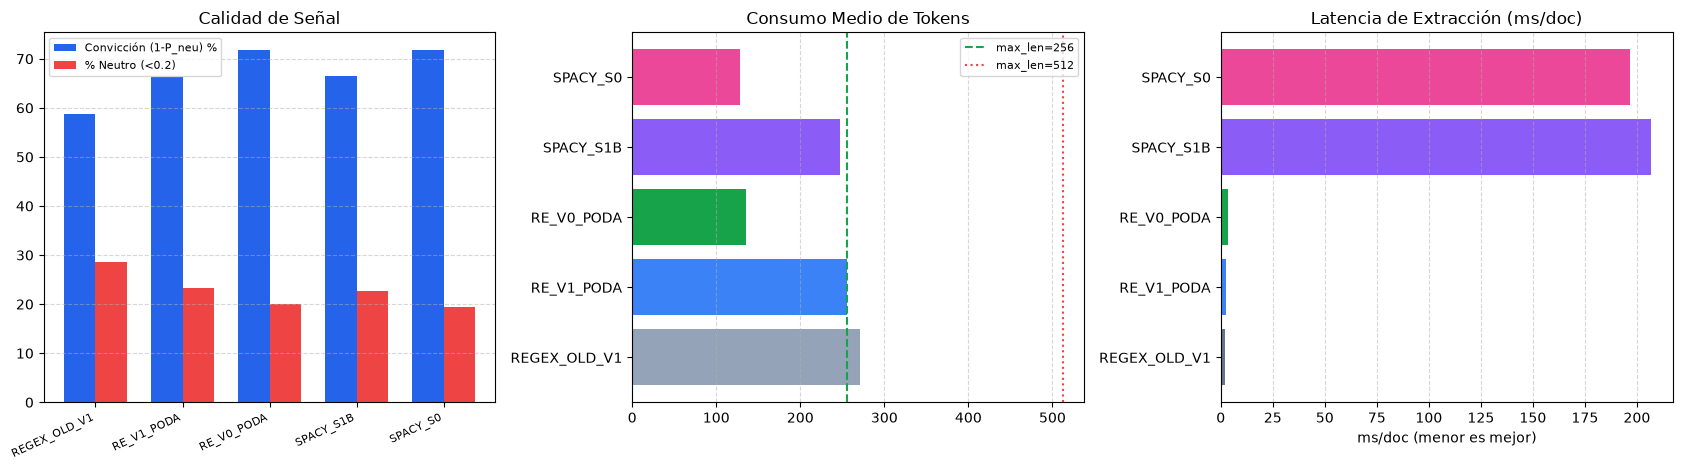

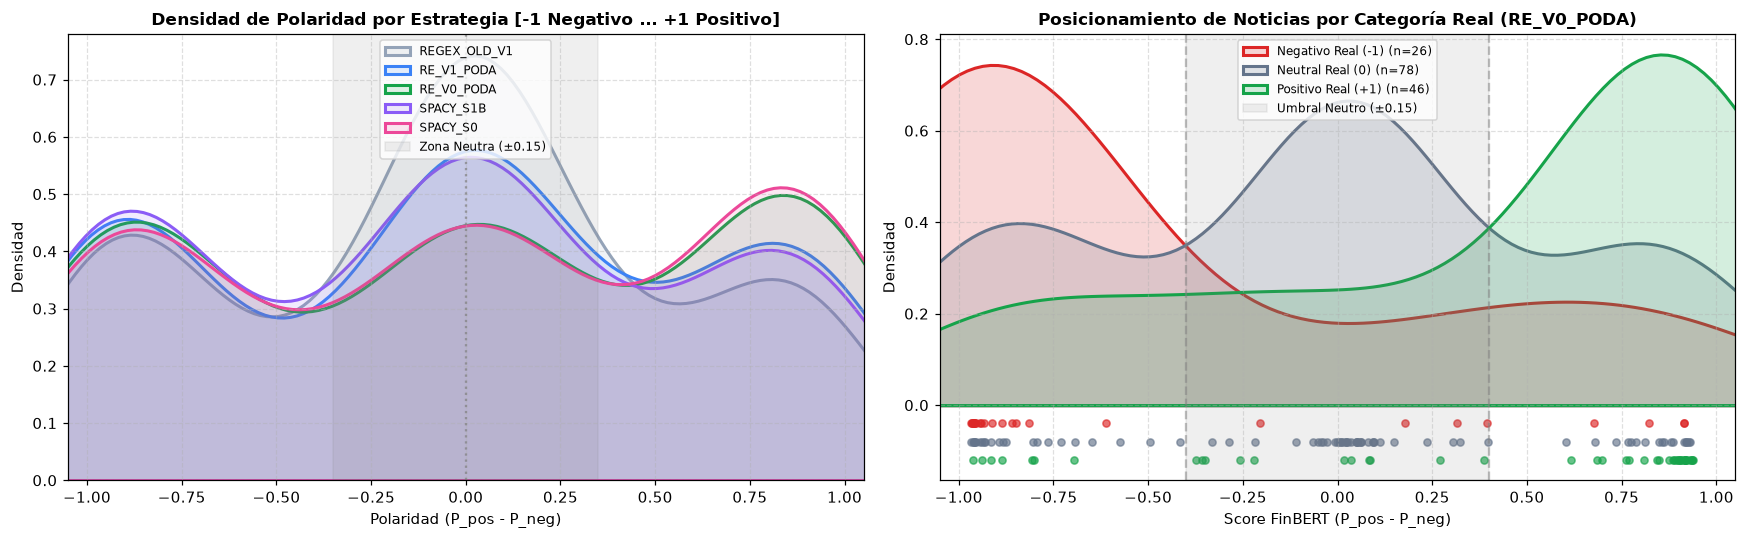

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
df_plot = df_resumen.copy()

x = np.arange(len(df_plot))
w = 0.36
axes[0].bar(x - w/2, df_plot["Convicción (1-P_neu)"] * 100, w, label="Convicción (1-P_neu) %", color="#2563eb")
axes[0].bar(x + w/2, df_plot["% Neutro (<0.2)"], w, label="% Neutro (<0.2)", color="#ef4444")
axes[0].set_title("Calidad de Señal")
axes[0].set_xticks(x)
axes[0].set_xticklabels(df_plot["Variante"], rotation=25, ha="right", fontsize=8)
axes[0].legend(fontsize=8)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

axes[1].barh(df_plot["Variante"], df_plot["Tokens medios"], color=["#94a3b8", "#3b82f6", "#16a34a", "#8b5cf6", "#ec4899"])
axes[1].axvline(256, color="#16a34a", linestyle="--", label="max_len=256")
axes[1].axvline(512, color="#ef4444", linestyle=":", label="max_len=512")
axes[1].set_title("Consumo Medio de Tokens")
axes[1].legend(fontsize=8)
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

axes[2].barh(df_plot["Variante"], df_plot["Extracción (ms/doc)"], color=["#64748b", "#3b82f6", "#16a34a", "#8b5cf6", "#ec4899"])
axes[2].set_title("Latencia de Extracción (ms/doc)")
axes[2].set_xlabel("ms/doc (menor es mejor)")
axes[2].grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Densidad de Polaridad Continua [-1, +1]: por estrategia y por etiqueta real (Ground Truth)
fig2, (ax_est, ax_gt) = plt.subplots(1, 2, figsize=(16, 5), dpi=110)

colores_est = {
    "REGEX_OLD_V1": "#94a3b8",
    "RE_V1_PODA":   "#3b82f6",
    "RE_V0_PODA":   "#16a34a",
    "SPACY_S1B":    "#8b5cf6",
    "SPACY_S0":     "#ec4899",
}
for nombre, col in colores_est.items():
    if nombre in res:
        sns.kdeplot(res[nombre]["sentiment"], ax=ax_est, label=nombre, color=col, fill=True, alpha=0.12, linewidth=2)

ax_est.axvspan(-0.35, 0.35, color="gray", alpha=0.12, label="Zona Neutra (±0.15)")
ax_est.axvline(0, color="gray", linestyle=":", alpha=0.7)
ax_est.set_xlim(-1.05, 1.05)
ax_est.set_title("Densidad de Polaridad por Estrategia [-1 Negativo ... +1 Positivo]", fontsize=11, fontweight="bold")
ax_est.set_xlabel("Polaridad (P_pos - P_neg)")
ax_est.set_ylabel("Densidad")
ax_est.legend(loc="upper center", fontsize=8)
ax_est.grid(True, linestyle="--", alpha=0.4)

if "df_gt" in locals() and "etiqueta_manual" in df_gt.columns and df_gt["etiqueta_manual"].notna().all():
    mapa_lbl = {-1: ("Negativo Real (-1)", "#dc2626"), 0: ("Neutral Real (0)", "#64748b"), 1: ("Positivo Real (+1)", "#16a34a")}
    df_viz = df_gt.copy()
    df_viz["sent_v0"] = res["RE_V0_PODA"]["sentiment"].values if "RE_V0_PODA" in res and len(res["RE_V0_PODA"]) == len(df_viz) else df_viz["RE_V0_sent"]
    for val, (etiq, c_lbl) in mapa_lbl.items():
        sub = df_viz[df_viz["etiqueta_manual"].astype(int) == val]["sent_v0"]
        if len(sub) > 1:
            sns.kdeplot(sub, ax=ax_gt, label=f"{etiq} (n={len(sub)})", color=c_lbl, fill=True, alpha=0.18, linewidth=2)
        ax_gt.scatter(sub, np.full(len(sub), -0.04 * (val + 2)), color=c_lbl, alpha=0.65, s=22)

ax_gt.axvspan(-0.40, 0.40, color="gray", alpha=0.12, label="Umbral Neutro (±0.15)")
ax_gt.axvline(-0.40, color="gray", linestyle="--", alpha=0.5)
ax_gt.axvline(0.40, color="gray", linestyle="--", alpha=0.5)
ax_gt.set_xlim(-1.05, 1.05)
ax_gt.set_title("Posicionamiento de Noticias por Categoría Real (RE_V0_PODA)", fontsize=11, fontweight="bold")
ax_gt.set_xlabel("Score FinBERT (P_pos - P_neg)")
ax_gt.set_ylabel("Densidad")
ax_gt.legend(loc="upper center", fontsize=8)
ax_gt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()